In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

In [2]:
def to_count(s):
    return pd.to_numeric(s.replace('-', 0), errors='raise').astype(int)

In [3]:
df_28_9= pd.read_excel('../data/raw/fz28_2026_09.xlsx', header=None, sheet_name="FZ 28.9")

regions = df_28_9.iloc[31:48, 1]
total_registrations_bundesland = to_count(df_28_9.iloc[31:48, 2])
electric_drive_registrations_bundesland = to_count(df_28_9.iloc[31:48, 5])
bev_registrations_bundesland = to_count(df_28_9.iloc[31:48, 7])
fcev_registrations_bundesland = to_count(df_28_9.iloc[31:48, 8])
phev_registrations_bundesland = to_count(df_28_9.iloc[31:48, 9])

assert df_28_9.iloc[30, 1].strip().lower() == 'januar - september 2026'
assert total_registrations_bundesland.sum() == df_28_9.iloc[30,2]
assert electric_drive_registrations_bundesland.sum() == df_28_9.iloc[30,5]
assert bev_registrations_bundesland.sum() == df_28_9.iloc[30,7]
assert phev_registrations_bundesland.sum() == df_28_9.iloc[30,9]

assert (electric_drive_registrations_bundesland ==
           bev_registrations_bundesland + phev_registrations_bundesland + fcev_registrations_bundesland).all()

regional = pd.DataFrame({
    'bundesland': regions.str.strip(),
    'total_ytd26': total_registrations_bundesland,
    'electric_ytd26': electric_drive_registrations_bundesland,
    'bev_ytd26': bev_registrations_bundesland,
    'phev_ytd26': phev_registrations_bundesland
}).reset_index(drop=True)

regional = regional[regional['bundesland'] != 'Sonstige'].reset_index(drop=True)
assert len(regional) == 16

regional['bev_share_ytd26'] = regional['bev_ytd26'] / regional['total_ytd26'] * 100
regional['phev_share_ytd26'] = regional['phev_ytd26'] / regional['total_ytd26'] * 100
regional['bev_phev_ratio_ytd26'] = regional['bev_ytd26'] / regional['phev_ytd26']

national_total = df_28_9.iloc[30, 2]

national_bev_share = df_28_9.iloc[30,7] / national_total * 100
national_phev_share = df_28_9.iloc[30,9] / national_total * 100
national_bev_phev_ratio = df_28_9.iloc[30,7] / df_28_9.iloc[30,9]
print(national_bev_share, national_phev_share)

regional['bev_share_vs_national_pp'] = regional['bev_share_ytd26'] - national_bev_share
regional['phev_share_vs_national_pp'] = regional['phev_share_ytd26'] - national_phev_share
regional['bev_phev_ratio_vs_national'] = regional['bev_phev_ratio_ytd26'] - national_bev_phev_ratio

display(regional.sort_values(by='bev_share_ytd26', ascending=False).round(2))

27.191670889972897 11.139131460195753


,bundesland,total_ytd26,electric_ytd26,bev_ytd26,phev_ytd26,bev_share_ytd26,phev_share_ytd26,bev_phev_ratio_ytd26,bev_share_vs_national_pp,phev_share_vs_national_pp,bev_phev_ratio_vs_national
10,Rheinland-Pfalz,85556,36699,28286,8413,33.06,9.83,3.36,5.87,-1.31,0.92
14,Schleswig-Holstein,59787,25289,19503,5786,32.62,9.68,3.37,5.43,-1.46,0.93
8,Niedersachsen,246132,100103,73285,26818,29.77,10.90,2.73,2.58,-0.24,0.29
0,Baden-Württemberg,305951,131655,90905,40749,29.71,13.32,2.23,2.52,2.18,-0.21
9,Nordrhein-Westfalen,443825,179349,130092,49256,29.31,11.10,2.64,2.12,-0.04,0.20
4,Bremen,12018,5069,3470,1599,28.87,13.31,2.17,1.68,2.17,-0.27
11,Saarland,23107,8574,6412,2161,27.75,9.35,2.97,0.56,-1.79,0.53
2,Berlin,41345,17120,11445,5673,27.68,13.72,2.02,0.49,2.58,-0.42
3,Brandenburg,37048,13559,9969,3590,26.91,9.69,2.78,-0.28,-1.45,0.34
1,Bayern,467237,170311,124289,46021,26.60,9.85,2.70,-0.59,-1.29,0.26


In [4]:
charging_stations = pd.read_parquet('../data/processed/charging_stations_clean.parquet')

In [5]:
ports_by_bundesland = (
    charging_stations
    .groupby('Bundesland', as_index=False)['Anzahl Ladepunkte']
    .sum()
    .rename(columns={'Anzahl Ladepunkte': 'charging_ports'})
)

ports_by_bundesland['charging_ports'] = ports_by_bundesland['charging_ports'].astype(int)

In [6]:
ports = pd.concat(
    [charging_stations[['Bundesland', f'Steckertypen{i}']]
     .rename(columns={f'Steckertypen{i}': 'connectors'})
     for i in range(1, 7)],
    ignore_index=True
).dropna(subset=['connectors'])

ports['is_dc'] = ports['connectors'].str.contains('DC')
ports['is_ac_only'] = ports['connectors'].str.contains('AC') & ~ports['is_dc']

assert (ports['is_dc'] | ports['is_ac_only']).all()

In [7]:
assert len(ports) == charging_stations['Anzahl Ladepunkte'].sum()

In [8]:
port_types_by_bundesland = (
    ports
    .groupby('Bundesland', as_index=False)[['is_dc', 'is_ac_only']]
    .sum()
    .rename(columns={'is_dc': 'dc_ports', 'is_ac_only': 'ac_only_ports'})
)

In [9]:
infrastructure = ports_by_bundesland.merge(
    port_types_by_bundesland,
    on='Bundesland',
    validate='one_to_one'
)

assert len(infrastructure) == 16
assert (infrastructure['charging_ports'] == infrastructure['dc_ports'] + infrastructure['ac_only_ports']).all()

infrastructure['dc_port_share'] = (
    infrastructure['dc_ports'] / (infrastructure['dc_ports'] + infrastructure['ac_only_ports']) * 100
)

display(infrastructure.round(2))

,Bundesland,charging_ports,dc_ports,ac_only_ports,dc_port_share
0,Baden-Württemberg,20653,2857,17796,13.83
1,Bayern,22500,4298,18202,19.10
2,Berlin,4432,589,3843,13.29
3,Brandenburg,2661,700,1961,26.31
4,Bremen,854,116,738,13.58
5,Hamburg,2554,443,2111,17.35
6,Hessen,8660,1557,7103,17.98
7,Mecklenburg-Vorpommern,1643,364,1279,22.15
8,Niedersachsen,11828,2622,9206,22.17
9,Nordrhein-Westfalen,22882,4416,18466,19.30


In [10]:
population = pd.read_excel('../data/raw/12411-0021_de.xlsx', header=None)

name_cols = list(range(1, 47, 3))
assert (population.iloc[4, [c + 2 for c in name_cols]] == 'Insgesamt').all()

population_final = pd.DataFrame({
    'bundesland': [population.iloc[3, c].strip() for c in name_cols],
    'population': pd.to_numeric(population.iloc[24, [c + 2 for c in name_cols]]).to_numpy()
})

population_final.sort_values(by='population',ascending=False)
print(population.iloc[3:6, 0:7])
print(population.iloc[24, 0])

                           0                  1         2          3         4         5          6
3  Stichtag zum Quartalsende  Baden-Württemberg       NaN        NaN    Bayern       NaN        NaN
4                        NaN           männlich  weiblich  Insgesamt  männlich  weiblich  Insgesamt
5                 30.09.2021            5525810   5597583   11123393   6532463   6644181   13176644
30.06.2026


/Users/cankale/miniforge3/envs/auto_env/lib/python3.12/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [11]:
assert len(population_final) == 16
assert set(population_final['bundesland']) == set(regional['bundesland'])
print(population_final['population'].sum())

83298787


In [12]:
population_final.to_parquet('../data/processed/population_by_bundesland.parquet', index=False)

In [13]:
area = pd.read_excel('../data/raw/11111-0001_de.xlsx')

rows = list(range(4, 20))

area_final = pd.DataFrame({
    'bundesland': [area.iloc[r, 0].strip() for r in rows],
    'area_in_sqkm': pd.to_numeric(area.iloc[rows , 1]).to_numpy()
})



assert area.iloc[20, 0].strip() == "Insgesamt"
insgesamt = area.iloc[20, 1]

assert np.isclose(area_final['area_in_sqkm'].sum(), insgesamt)
assert len(area_final) == 16
assert set(area_final['bundesland']) == set(regional['bundesland'])

/Users/cankale/miniforge3/envs/auto_env/lib/python3.12/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [14]:
area_final.to_parquet('../data/processed/area_by_bundesland.parquet', index=False)

In [15]:
def key(s):
    return s.replace('-', '').replace('\n', '').replace(' ', '').lower()

In [16]:
fz2_3 = pd.read_excel('../data/raw/fz2_2026.xlsx', header=None, sheet_name='FZ 2.3')

lookup = {key(b): b for b in regional['bundesland']}
state_names = [lookup[key(n)] for n in fz2_3.iloc[7, 4:20]]


row = 89
assert fz2_3.iloc[row].astype(str).str.contains('PERSONENKRAFTWAGEN INSGESAMT').any()

state_stock = to_count(fz2_3.iloc[row, 4:20])
sonstige_stock = int(fz2_3.iloc[row, 20])
germany_stock = int(fz2_3.iloc[row, 21])

assert state_stock.sum() + sonstige_stock == germany_stock

car_stock = pd.DataFrame({
    'bundesland': state_names,
    'car_stock': state_stock.to_numpy()
})

assert len(car_stock) == 16
assert set(car_stock['bundesland']) == set(regional['bundesland'])


In [17]:
car_stock.to_parquet('../data/processed/car_stock_by_bundesland.parquet', index=False)

Merging all data

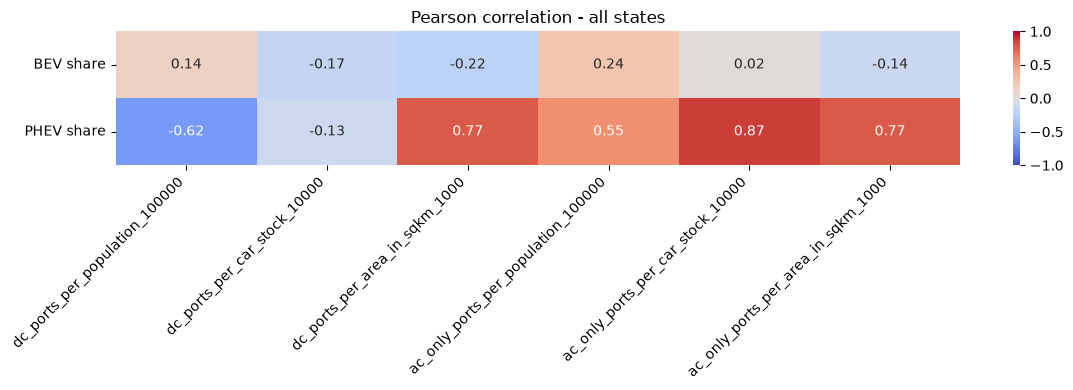

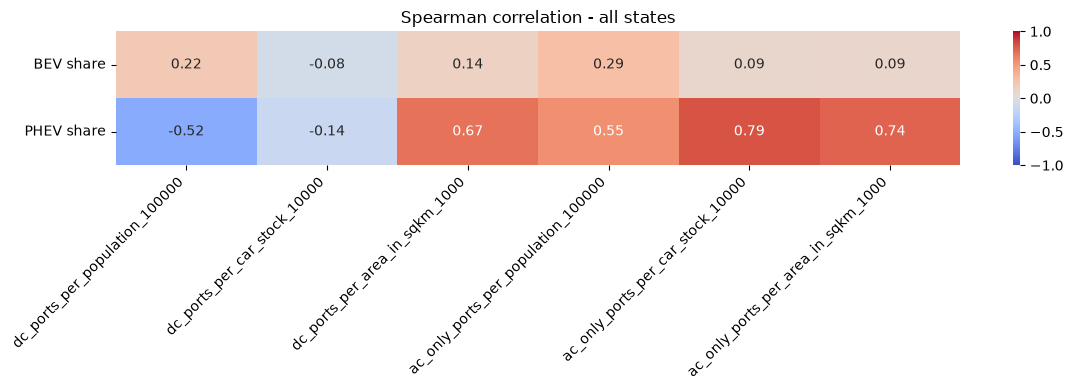

In [18]:
infrastructure = infrastructure.rename(columns={'Bundesland' : 'bundesland'})

tables = [regional,infrastructure, population_final, area_final, car_stock]

regional_merged = tables[0]

for df in tables[1:]:
    regional_merged = regional_merged.merge(
        df, how='outer', on='bundesland', validate='one_to_one', indicator=True
    )
    assert (regional_merged["_merge"] == "both").all()
    regional_merged = regional_merged.drop(columns="_merge")

assert len(regional_merged) == 16


normalization_cols = ['population', 'car_stock', 'area_in_sqkm']
target_cols = ['charging_ports', 'dc_ports', 'ac_only_ports']
multipliers = [100000, 10000, 1000]
for t in target_cols:
    for m, n in zip(multipliers, normalization_cols):
        regional_merged[f'{t}_per_{n}_{m}'] = regional_merged[t] / regional_merged[n] * m


regional_merged['population_density'] = regional_merged['population'] / regional_merged['area_in_sqkm']
regional_merged['log_population_density'] = np.log(regional_merged['population_density'])

def plot_correlation(df, methods=('pearson', 'spearman'), label='all states'):
    for me in methods:
        densities = df[density_cols]

        bev_phev_corr = pd.DataFrame({
            'BEV share': densities.corrwith(df['bev_share_ytd26'], method=me),
            'PHEV share': densities.corrwith(df['phev_share_ytd26'], method=me)
        }).T

        fig, ax = plt.subplots(figsize=(12, 4))

        ax = sns.heatmap(bev_phev_corr, annot=True, vmin=-1, vmax=1, cmap='coolwarm', fmt='.2f', ax=ax)
        ax.set_title(f"{me.capitalize()} correlation - {label}")
        ax.tick_params(axis='x', labelrotation=45)
        ax.tick_params(axis='y', labelrotation=0)

        plt.setp(ax.get_xticklabels(), ha='right')

        plt.tight_layout()
        plt.show()


density_cols = []
for t in target_cols[1:]:
    for m, n in zip(multipliers, normalization_cols):
        density_cols.append(f'{t}_per_{n}_{m}')


plot_correlation(df= regional_merged)

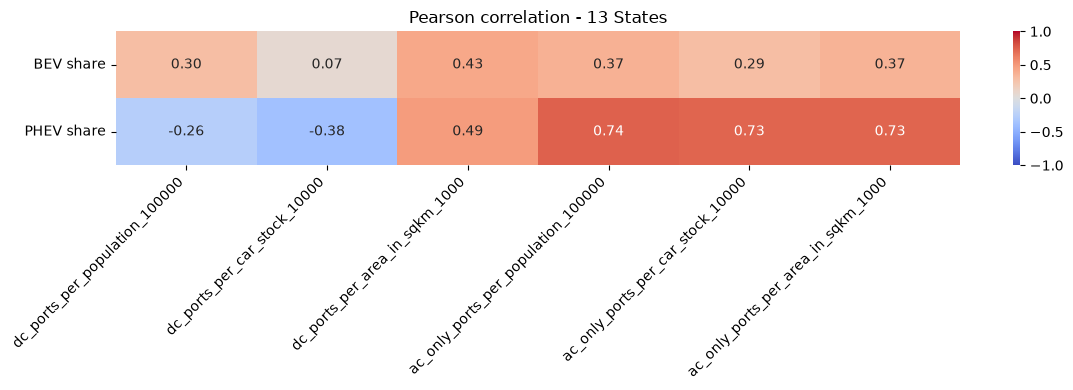

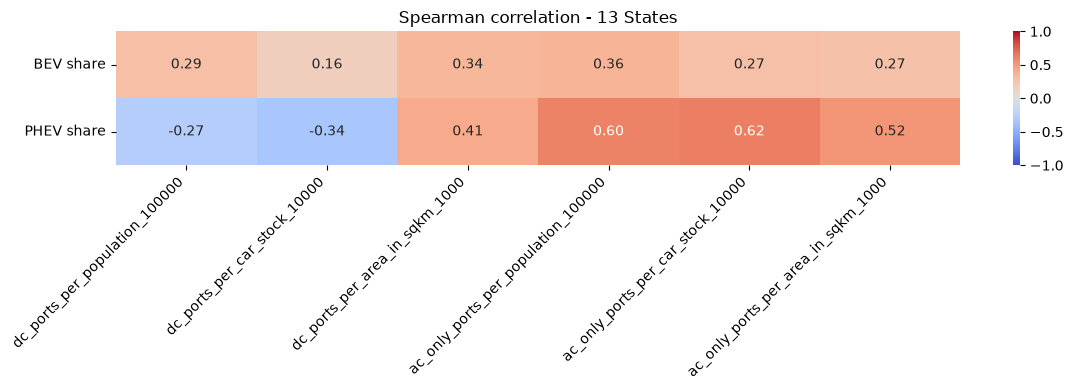

In [19]:
regional_merged_without_BHB = regional_merged[~regional_merged['bundesland'].isin(['Berlin', 'Hamburg', 'Bremen'])]

plot_correlation(regional_merged_without_BHB, label='13 States')

In [20]:
from scipy.stats import pearsonr, spearmanr


def p_test(df, method, density_cols):
    metrics = ['bev_share_ytd26', 'phev_share_ytd26']
    results = []
    if method == 'pearson':
        test = pearsonr
    elif method == 'spearman':
        test = spearmanr
    else:
        raise ValueError('Unidentified method passed!')
    
    for d in density_cols:
        for met in metrics:
            result = test(df[d], df[met])
            dictionary = {
                'share': met,
                'density': d,
                'method': method,
                'coef': result.statistic,
                'p_value': result.pvalue
                }
            results.append(dictionary)


    return pd.DataFrame(results)


result_dic = {
    'all states' : regional_merged,
    '13 states' : regional_merged_without_BHB
}
lst = []
for met in ['pearson', 'spearman']:
    for title, sample in result_dic.items():
        ergebnis = p_test(sample, method=met,density_cols=density_cols)
        ergebnis['sample'] = title
        ergebnis['n'] = len(sample)
        lst.append(ergebnis)

p_values = pd.concat(lst, ignore_index=True)
phev_results = p_values[p_values['share'].str.contains('phev')]

display(
    phev_results
    .sort_values(['density', 'method', 'sample'])
    .round({'coef': 2, 'p_value': 3})

)

,share,density,method,coef,p_value,sample,n
23,phev_share_ytd26,ac_only_ports_per_area_in_sqkm_1000,pearson,0.73,0.005,13 states,13
11,phev_share_ytd26,ac_only_ports_per_area_in_sqkm_1000,pearson,0.77,0.001,all states,16
47,phev_share_ytd26,ac_only_ports_per_area_in_sqkm_1000,spearman,0.52,0.067,13 states,13
35,phev_share_ytd26,ac_only_ports_per_area_in_sqkm_1000,spearman,0.74,0.001,all states,16
21,phev_share_ytd26,ac_only_ports_per_car_stock_10000,pearson,0.73,0.005,13 states,13
9,phev_share_ytd26,ac_only_ports_per_car_stock_10000,pearson,0.87,0.000,all states,16
45,phev_share_ytd26,ac_only_ports_per_car_stock_10000,spearman,0.62,0.024,13 states,13
33,phev_share_ytd26,ac_only_ports_per_car_stock_10000,spearman,0.79,0.000,all states,16
19,phev_share_ytd26,ac_only_ports_per_population_100000,pearson,0.74,0.004,13 states,13
7,phev_share_ytd26,ac_only_ports_per_population_100000,pearson,0.55,0.028,all states,16


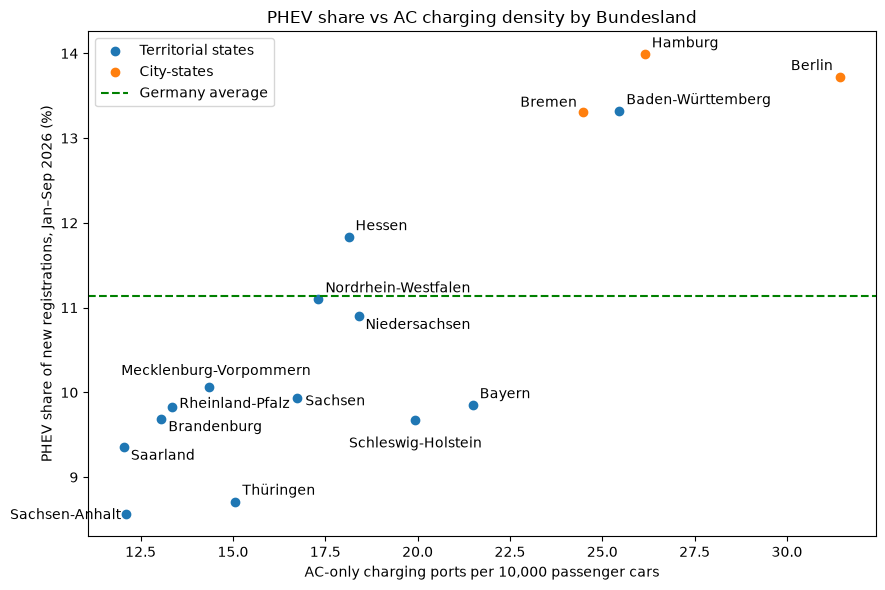

In [21]:
fig, ax = plt.subplots(figsize=(9,6))

city_mask = regional_merged['bundesland'].isin(['Berlin', 'Hamburg', 'Bremen'])

ax.scatter(regional_merged[~city_mask]['ac_only_ports_per_car_stock_10000'], y=regional_merged[~city_mask]['phev_share_ytd26'], label='Territorial states')
ax.scatter(regional_merged[city_mask]['ac_only_ports_per_car_stock_10000'], y=regional_merged[city_mask]['phev_share_ytd26'], label='City-states')
label_positions = {
    'Berlin': ((-5,5), 'right'),
    'Bremen': ((-4,4), 'right'),
    'Schleswig-Holstein': ((0,-20), 'center'),
    'Sachsen-Anhalt': ((-4,-4), 'right'),
    'Sachsen': ((6,-5), 'left'),
    'Rheinland-Pfalz': ((5,-1), 'left'),
    'Saarland': ((5,-9), 'left'),
    'Niedersachsen': ((5,-9), 'left'),
    'Mecklenburg-Vorpommern': ((5,9), 'center'),
    'Brandenburg': ((5,-9), 'left')
}
for _, row in regional_merged.iterrows():
    offset, ha = label_positions.get(row['bundesland'], ((5,5), 'left'))
    ax.annotate(row['bundesland'], 
                (row['ac_only_ports_per_car_stock_10000'], row['phev_share_ytd26']), 
                xytext=offset, ha=ha,
                textcoords='offset points')


ax.axhline(national_phev_share, linestyle='--', label='Germany average', color='green')
ax.set_xlabel("AC-only charging ports per 10,000 passenger cars")
ax.set_ylabel("PHEV share of new registrations, Jan–Sep 2026 (%)")
ax.set_title("PHEV share vs AC charging density by Bundesland")
ax.legend()
plt.tight_layout()
fig.savefig('../reports/figures/phev_vs_ac_density.png', dpi=150, bbox_inches='tight')
plt.show()

In [22]:
display(
    regional_merged[['bundesland', 'population_density']].sort_values(by='population_density', ascending=False)
)

,bundesland,population_density
2,Berlin,4151.906589
5,Hamburg,2475.316850
4,Bremen,1682.090513
9,Nordrhein-Westfalen,526.029875
11,Saarland,390.395838
0,Baden-Württemberg,314.056706
6,Hessen,296.499277
12,Sachsen,217.213627
10,Rheinland-Pfalz,207.221084
1,Bayern,187.524540


In [23]:
density_lst = []
for met in ['pearson', 'spearman']:
    for title, sample in result_dic.items():
        ergebnis = p_test(sample, method=met,density_cols=['population_density', 'log_population_density'])
        ergebnis['sample'] = title
        ergebnis['n'] = len(sample)
        density_lst.append(ergebnis)

density_p_values = pd.concat(density_lst, ignore_index=True)

display(
    density_p_values.sort_values(by=['p_value', 'coef']).round({'coef': 2, 'p_value': 3})
)

,share,density,method,coef,p_value,sample,n
3,phev_share_ytd26,log_population_density,pearson,0.82,0.000,all states,16
1,phev_share_ytd26,population_density,pearson,0.74,0.001,all states,16
9,phev_share_ytd26,population_density,spearman,0.68,0.004,all states,16
11,phev_share_ytd26,log_population_density,spearman,0.68,0.004,all states,16
7,phev_share_ytd26,log_population_density,pearson,0.50,0.085,13 states,13
5,phev_share_ytd26,population_density,pearson,0.47,0.102,13 states,13
13,phev_share_ytd26,population_density,spearman,0.43,0.144,13 states,13
15,phev_share_ytd26,log_population_density,spearman,0.43,0.144,13 states,13
6,bev_share_ytd26,log_population_density,pearson,0.36,0.224,13 states,13
4,bev_share_ytd26,population_density,pearson,0.31,0.301,13 states,13


In [24]:
density_ac_lst = []

for title, sample in result_dic.items():
    X = sample['log_population_density']
    Y= sample['ac_only_ports_per_car_stock_10000']
    for method in ['pearson', 'spearman']:
        result = pearsonr(X, Y) if method == 'pearson' else spearmanr(X, Y)
        density_ac_lst.append({
            'sample': title,
            'method': method, 
            'coef': result.statistic,
            'p_value': result.pvalue
        })

density_ac = pd.DataFrame(density_ac_lst)

display(
    density_ac
    .round({'coef': 2, 'p_value': 3})
)

,sample,method,coef,p_value
0,all states,pearson,0.79,0.000
1,all states,spearman,0.60,0.015
2,13 states,pearson,0.37,0.217
3,13 states,spearman,0.26,0.384


In [25]:
partial_lst = []


for title, sample in result_dic.items():
    x = sample['log_population_density']

    phev_slope, phev_intercept = np.polyfit(x, sample['phev_share_ytd26'], 1)
    phev_resid = sample['phev_share_ytd26'] - (phev_slope * x + phev_intercept)

    ac_slope, ac_intercept = np.polyfit(x, sample['ac_only_ports_per_car_stock_10000'], 1)
    ac_resid = sample['ac_only_ports_per_car_stock_10000'] - (ac_slope * x + ac_intercept)

    for method in ['pearson', 'spearman']:
        result_partial = pearsonr(phev_resid, ac_resid) if method == 'pearson' else spearmanr(phev_resid, ac_resid)
        partial_lst.append({
            'sample': title,
            'method': method,
            'coef': result_partial.statistic,
            'p_value': result_partial.pvalue
        })

partial = pd.DataFrame(partial_lst)
display(
    partial
    .round({'coef': 2, 'p_value': 3})
)

,sample,method,coef,p_value
0,all states,pearson,0.62,0.010
1,all states,spearman,0.47,0.068
2,13 states,pearson,0.68,0.011
3,13 states,spearman,0.59,0.035


Estimated regional BMW registrations

In [26]:
fz2_4 = pd.read_excel('../data/raw/fz2_2026.xlsx', header=7, sheet_name='FZ 2.4')
fz2_4 = fz2_4.iloc[:, 1:]
fz2_4.columns = [
    lookup.get(key(c), c) if isinstance(c, str) else c
    for c in fz2_4.columns
]
fz2_4 = fz2_4.rename(columns={
    'Hersteller\n': 'manufacturer',
    '\nHandelsname': 'trade_name',
    'Typ-Schl.-Nr.': 'type_key'
})

fz2_4_copy = fz2_4.copy()
fz2_4_copy[['manufacturer', 'trade_name']] = fz2_4_copy[['manufacturer', 'trade_name']].ffill()

is_zusammen = fz2_4_copy['trade_name'].astype('string').str.strip().str.upper().eq('ZUSAMMEN')
is_bmw = fz2_4_copy['manufacturer'] == 'BMW'

bmw_zusammen = fz2_4_copy[is_bmw & is_zusammen]
assert len(bmw_zusammen) == 1

bmw_data = fz2_4_copy[is_bmw & ~is_zusammen].drop(columns='Deutschland')

In [27]:
not_bmw_pattern = 'MINI|COOPER|ONE|ACEMAN|PACEMAN|COUNTRYMAN|CLUBMAN|JCW|GOGGO'
not_bmw = bmw_data['trade_name'].astype(str).str.upper().str.contains(not_bmw_pattern)

bmw_brand = bmw_data[~not_bmw]
bmw_stock = bmw_brand.loc[:, 'Baden-Württemberg':'Sonstige'].apply(to_count).sum()
print(bmw_stock[['Baden-Württemberg', 'Bayern']])

Baden-Württemberg    522719
Bayern               898567
dtype: int64


In [28]:
total_check = bmw_data.loc[:, 'Baden-Württemberg':'Sonstige'].apply(to_count).sum()
zusammen_values = bmw_zusammen.loc[:, 'Baden-Württemberg':'Sonstige'].apply(to_count).iloc[0]
assert total_check.eq(zusammen_values).all()

In [29]:
brands = pd.read_parquet('../data/processed/brand_registrations.parquet')
bmw_national = brands.loc[brands['brand'] == 'bmw', 'total_ytd26'].item()
assert bmw_national == 189320

In [30]:
state_input = regional_merged[['bundesland', 'total_ytd26', 'car_stock']].rename(columns={'total_ytd26' : 'new_regs'})


assert df_28_9.iloc[47,1].strip() == 'Sonstige'
sonstige_df = pd.DataFrame({
    'bundesland': ['Sonstige'],
    'new_regs': [df_28_9.iloc[47,2]],
    'car_stock': [sonstige_stock]
})

model_input = pd.concat([state_input, sonstige_df], ignore_index=True)

model_input['bmw_stock'] = model_input['bundesland'].map(bmw_stock)


assert len(model_input) == 17
assert model_input['bmw_stock'].notna().all()
assert model_input['new_regs'].sum() == df_28_9.iloc[30, 2]
assert model_input['car_stock'].sum() == germany_stock
assert model_input['bmw_stock'].sum() == bmw_stock.sum()

In [31]:
model_input['registration_intensity'] = model_input['new_regs'] / model_input['car_stock']

for b in [0, 0.25,0.5,0.75,1]:
    col = f'bmw_est_beta_{b}'
    weights = model_input['bmw_stock'] * model_input['registration_intensity'] ** b
    estimates = bmw_national * weights / weights.sum()
    model_input[col] = estimates
    assert np.isclose(model_input[col].sum(), bmw_national)

est_cols = [c for c in model_input.columns if c.startswith('bmw_est_beta_')]
display(model_input[['bundesland'] + est_cols].round(0))

,bundesland,bmw_est_beta_0,bmw_est_beta_0.25,bmw_est_beta_0.5,bmw_est_beta_0.75,bmw_est_beta_1
0,Baden-Württemberg,28105.0,27838.0,27450.0,26943.0,26320.0
1,Bayern,48313.0,50705.0,52976.0,55094.0,57024.0
2,Berlin,4193.0,3894.0,3600.0,3312.0,3034.0
3,Brandenburg,3712.0,3186.0,2722.0,2315.0,1960.0
4,Bremen,1103.0,1067.0,1028.0,985.0,940.0
5,Hamburg,3044.0,3855.0,4859.0,6096.0,7611.0
6,Hessen,16072.0,17458.0,18878.0,20319.0,21766.0
7,Mecklenburg-Vorpommern,2003.0,1732.0,1491.0,1277.0,1089.0
8,Niedersachsen,14442.0,14729.0,14953.0,15112.0,15199.0
9,Nordrhein-Westfalen,38343.0,37502.0,36514.0,35389.0,34135.0


In [32]:
i = model_input[model_input['bundesland'] == 'Sonstige']

bmw_results = model_input[model_input['bundesland'] != 'Sonstige'].copy()

bmw_results['est_low'] = bmw_results[est_cols].min(axis=1)
bmw_results['est_high'] = bmw_results[est_cols].max(axis=1)
bmw_results['est_central'] = bmw_results['bmw_est_beta_0.5']

In [33]:
bmw_results['share_est_low'] = bmw_results['est_low'] / bmw_results['new_regs'] * 100
bmw_results['share_est_high'] = bmw_results['est_high'] / bmw_results['new_regs'] * 100
bmw_results['share_est_central'] = bmw_results['est_central'] / bmw_results['new_regs'] * 100

result_cols = ['bundesland', 'new_regs', 'est_low', 'est_central', 'est_high',
               'share_est_low', 'share_est_central', 'share_est_high']

display(
    bmw_results[result_cols]
    .sort_values('est_central', ascending=False)
    .round({'est_low': 0, 'est_central': 0, 'est_high': 0,
            'share_est_low': 1,'share_est_central': 1, 'share_est_high': 1 })
)

,bundesland,new_regs,est_low,est_central,est_high,share_est_low,share_est_central,share_est_high
1,Bayern,467237,48313.0,52976.0,57024.0,10.3,11.3,12.2
9,Nordrhein-Westfalen,443825,34135.0,36514.0,38343.0,7.7,8.2,8.6
0,Baden-Württemberg,305951,26320.0,27450.0,28105.0,8.6,9.0,9.2
6,Hessen,248033,16072.0,18878.0,21766.0,6.5,7.6,8.8
8,Niedersachsen,246132,14442.0,14953.0,15199.0,5.9,6.1,6.2
10,Rheinland-Pfalz,85556,7522.0,9145.0,10914.0,8.8,10.7,12.8
5,Hamburg,94331,3044.0,4859.0,7611.0,3.2,5.2,8.1
12,Sachsen,64344,3344.0,4256.0,5318.0,5.2,6.6,8.3
14,Schleswig-Holstein,59787,3550.0,4202.0,4883.0,5.9,7.0,8.2
2,Berlin,41345,3034.0,3600.0,4193.0,7.3,8.7,10.1


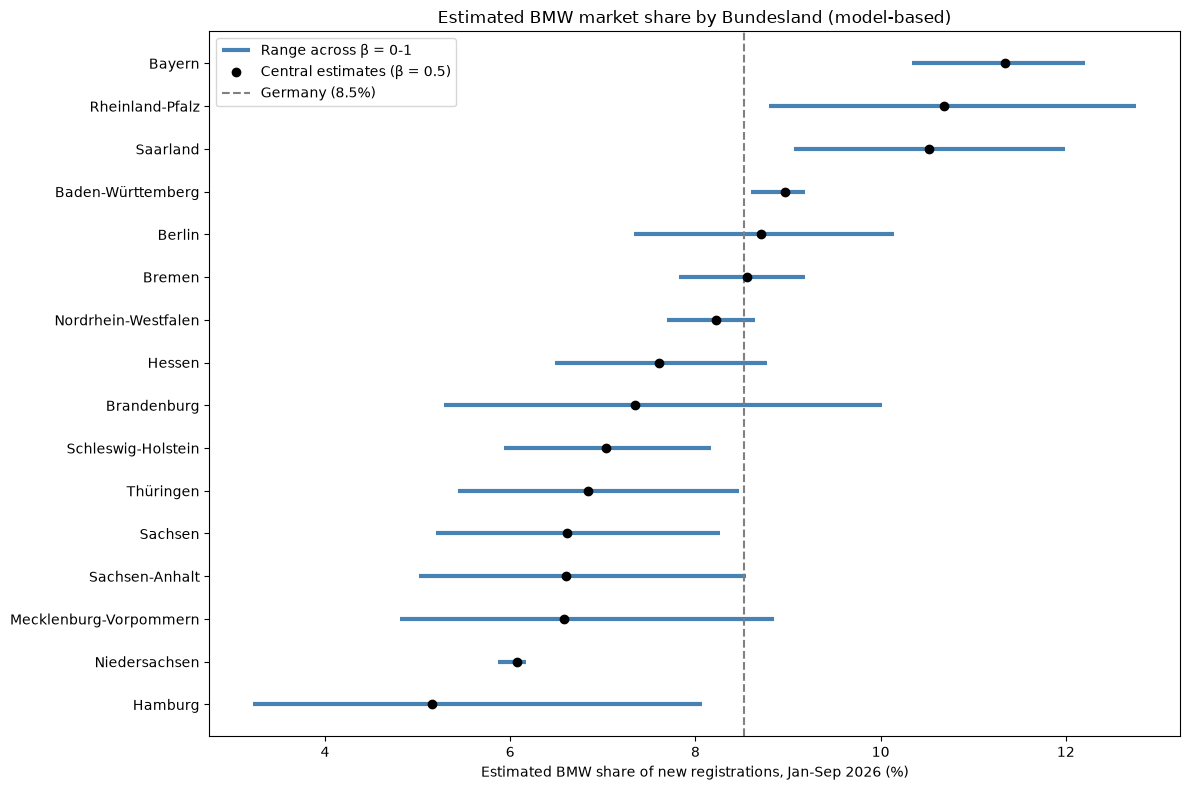

In [34]:
plot_data = bmw_results.sort_values('share_est_central').reset_index(drop=True)
y = range(len(plot_data))

fig, ax = plt.subplots(figsize=(12,8))

ax.hlines(y, plot_data['share_est_low'], plot_data['share_est_high'],
          color='steelblue', linewidth=3, label='Range across β = 0-1')
ax.scatter(plot_data['share_est_central'], y,
           color='black', zorder=3, label='Central estimates (β = 0.5)')

bmw_national_share = bmw_national / model_input['new_regs'].sum() * 100
ax.axvline(bmw_national_share, linestyle='--', color='grey',
           label=f'Germany ({bmw_national_share:.1f}%)')
ax.set_yticks(y)
ax.set_yticklabels(plot_data['bundesland'])
ax.set_xlabel('Estimated BMW share of new registrations, Jan-Sep 2026 (%)')
ax.set_title('Estimated BMW market share by Bundesland (model-based)')
ax.legend()

plt.tight_layout()
fig.savefig('../reports/figures/bmw_estimated_share_by_state.png', dpi=150, bbox_inches='tight')
plt.show()

In [35]:
compare_data = fz2_4.copy()


mask = (
    compare_data['manufacturer'].astype('string').str.strip().str.upper().isin([
        'INSGESAMT',
        '© KRAFTFAHRT-BUNDESAMT, FLENSBURG'
    ])
    | compare_data['trade_name'].astype('string')
        .str.strip().str.upper().eq('ZUSAMMEN')
).fillna(False)


compare_data = compare_data.loc[~mask].copy()
# Remove rows without national registration counts
compare_data = compare_data.dropna(subset=['Deutschland'])
compare_data['manufacturer'] = compare_data['manufacturer'].ffill()

compare_data = compare_data.drop(columns=['trade_name', 'type_key'])


regional_cols = compare_data.columns.difference(['manufacturer', 'Deutschland'])
count_cols = compare_data.columns.difference(['manufacturer'])
compare_data[count_cols] = compare_data[count_cols].apply(to_count)

regional_total = compare_data[regional_cols].sum(axis=1)
assert regional_total.eq(compare_data['Deutschland']).all()



compare_data['manufacturer'] = (
    compare_data['manufacturer']
    .str.replace(r'\s+\([^)]*\)$', '', regex=True)
    .str.strip()
    .replace({'DAIMLER': 'MERCEDES-BENZ'})
)


grouped = compare_data.groupby('manufacturer').sum(numeric_only=True)



assert grouped.loc['BMW', 'Bayern'] == to_count(bmw_zusammen['Bayern']).iloc[0]
assert grouped.loc['BMW', 'Deutschland'] == to_count(bmw_zusammen['Deutschland']).iloc[0]

# BMW-brand vehicle counts
bmw_bayern = bmw_stock['Bayern']
bmw_germany = bmw_stock.sum() # bmw_stock excludes Deutschland (total column), so .sum() here is the national total
bmw_non_bayern = bmw_germany - bmw_bayern


total_bayern = grouped['Bayern'].sum()
total_non_bayern = grouped['Deutschland'].sum() - total_bayern

bmw_home_index = (
    (bmw_bayern / total_bayern)
    /
    (bmw_non_bayern / total_non_bayern)
)


bayern_data = grouped['Bayern']
non_bayern_data = grouped['Deutschland'] - grouped['Bayern']

bayern_share = bayern_data / total_bayern
non_bayern_share = non_bayern_data / total_non_bayern

home_index = bayern_share / non_bayern_share


# Select top 20 by national stock
top20_manufacturers = (
    grouped
    .drop(index='SONSTIGE HERSTELLER', errors='ignore')
    .nlargest(20, 'Deutschland')
    .index
)

home_index = home_index.loc[top20_manufacturers]
home_index.loc['BMW brand (excl. MINI)'] = bmw_home_index
home_index = home_index.sort_values(ascending=False)

home_index

manufacturer
BMW brand (excl. MINI)    1.659751
BMW                       1.609026
AUDI                      1.358965
SEAT                      1.281437
FCA                       1.134559
STELLANTIS                1.098463
SKODA                     1.020920
OPEL                      0.992577
TOYOTA EUROPE             0.955658
VOLKSWAGEN                0.943352
MAZDA                     0.941812
DACIA                     0.865545
MERCEDES-BENZ             0.833208
FORD                      0.820194
PEUGEOT                   0.809480
KIA MOTORS                0.798959
VOLVO                     0.785611
HYUNDAI MOTOR             0.783560
NISSAN                    0.737271
RENAULT                   0.690505
CITROEN                   0.647476
dtype: float64

In [36]:
# Combine regional market shares
brand_shares = pd.DataFrame({
    'bayern_share': bayern_share * 100,
    'non_bayern_share': non_bayern_share * 100
})

# Calculate home index directly from the shares
brand_shares['home_index'] = (
    brand_shares['bayern_share'] /
    brand_shares['non_bayern_share']
)

# Select top 20 manufacturers
brand_shares = brand_shares.loc[top20_manufacturers].copy()

# Add BMW brand-only data
brand_shares.loc['BMW brand (excl. MINI)'] = {
    'bayern_share': bmw_bayern / total_bayern * 100,
    'non_bayern_share': bmw_non_bayern / total_non_bayern * 100,
    'home_index': bmw_home_index
}

# Remove BMW manufacturer group for brand ranking
brand_ranking = brand_shares.drop(index='BMW')

# Ranking outside Bavaria
rest_ranked = brand_ranking.sort_values(
    'non_bayern_share',
    ascending=False
)

# Ranking within Bavaria
bayern_ranked = brand_ranking.sort_values(
    'bayern_share',
    ascending=False
)

display(rest_ranked)
display(bayern_ranked)

# BMW rankings
bmw_rest_rank = (
    rest_ranked.index.get_loc('BMW brand (excl. MINI)') + 1
)

bmw_bayern_rank = (
    bayern_ranked.index.get_loc('BMW brand (excl. MINI)') + 1
)

print(f'BMW brand rank in Bavaria: {bmw_bayern_rank}')
print(f'BMW brand rank outside Bavaria: {bmw_rest_rank}')

,bayern_share,non_bayern_share,home_index
manufacturer,,,
VOLKSWAGEN,19.915835,21.111770,0.943352
MERCEDES-BENZ,8.897488,10.678595,0.833208
FORD,5.596540,6.823435,0.820194
OPEL,6.576083,6.625260,0.992577
BMW brand (excl. MINI),10.644657,6.413406,1.659751
AUDI,8.551293,6.292503,1.358965
SKODA,5.927844,5.806376,1.020920
RENAULT,2.555629,3.701102,0.690505
SEAT,4.241624,3.310051,1.281437


,bayern_share,non_bayern_share,home_index
manufacturer,,,
VOLKSWAGEN,19.915835,21.111770,0.943352
BMW brand (excl. MINI),10.644657,6.413406,1.659751
MERCEDES-BENZ,8.897488,10.678595,0.833208
AUDI,8.551293,6.292503,1.358965
OPEL,6.576083,6.625260,0.992577
SKODA,5.927844,5.806376,1.020920
FORD,5.596540,6.823435,0.820194
SEAT,4.241624,3.310051,1.281437
FCA,3.573957,3.150085,1.134559


BMW brand rank in Bavaria: 2
BMW brand rank outside Bavaria: 5


### BMW's regional market position

- **Main Finding:** VW is 1st both in Bayern (19.9%) and in the rest of Germany (21.1%). 
- **Bavaria:** The BMW brand ranks 2nd by market share among the 20 largest manufacturers by national stock.
- **Rest of Germany:** BMW ranks 5th, indicating a stronger relative position in its home state.
- **Home-market concentration:** The home index compares BMW's Bavarian market share with its share in the rest of Germany. An index above 1 indicates that BMW is disproportionately represented in Bavaria.

**Methodology:** The analysis uses vehicle stock (*Fahrzeugbestand*), not annual new registrations. BMW-brand figures exclude MINI. Market shares use the full vehicle stock as the denominator, while the rankings compare the selected leading manufacturers. Therefore, the results describe the geographic distribution of vehicles in use, not current purchasing behavior.

**Source:** Kraftfahrt-Bundesamt (KBA), FZ 2.4

In [37]:
states = bmw_stock.index.drop('Sonstige')

vw_against_total = {}
for col in states:
    state_sum = grouped[col].sum()
    vw_against_total[col] = float(grouped.loc['VOLKSWAGEN'].loc[col] / state_sum)



bmw_against_total = {}
for col in states:
    state_sum = grouped[col].sum()
    bmw_against_total[col] = float(bmw_stock.loc[col] / state_sum)




bmw_and_vw = pd.DataFrame({
    "bmw_share": bmw_against_total,
    "vw_share": vw_against_total 
})


bmw_and_vw[['bmw_share', 'vw_share']] *= 100


bmw_and_vw['gap'] = bmw_and_vw['vw_share'] - bmw_and_vw['bmw_share'] 

bmw_and_vw = bmw_and_vw.sort_values(by='gap', ascending=False)

display(
    bmw_and_vw    
)

assert np.isclose(bmw_and_vw['bmw_share'].loc['Bayern'],brand_shares.loc['BMW brand (excl. MINI)', 'bayern_share'])

,bmw_share,vw_share,gap
Niedersachsen,5.384438,27.929745,22.545307
Schleswig-Holstein,5.178003,22.859484,17.681481
Sachsen-Anhalt,4.373371,21.757175,17.383803
Mecklenburg-Vorpommern,4.193246,21.514988,17.321743
Sachsen,4.533979,20.992982,16.459003
Thüringen,4.739388,20.627343,15.887954
Bremen,6.821393,21.987839,15.166446
Hamburg,7.037910,22.190970,15.153059
Brandenburg,4.616611,19.652357,15.035746
Nordrhein-Westfalen,6.706588,19.985666,13.279078


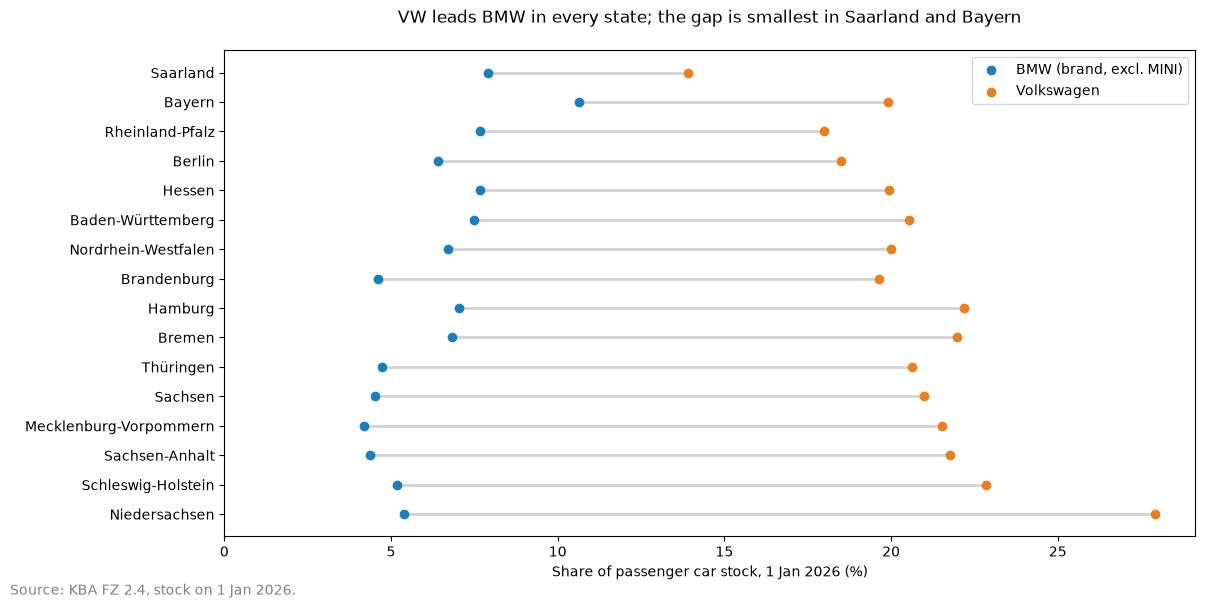

In [38]:
fig, ax = plt.subplots(figsize=(12,6))

ax.hlines(y=bmw_and_vw.index, xmin=bmw_and_vw['bmw_share'],xmax=bmw_and_vw['vw_share'], 
          color='lightgrey', linewidth=2)

ax.scatter(y=bmw_and_vw.index,x=bmw_and_vw['bmw_share'], color="#1a80bb", label="BMW (brand, excl. MINI)", zorder=3)
ax.scatter(y=bmw_and_vw.index,x=bmw_and_vw['vw_share'], color='#EA801C', label='Volkswagen', zorder=3)
ax.set_yticks(bmw_and_vw.index)
ax.set_yticklabels(bmw_and_vw.index)
ax.set_xlim(0)
ax.set_title("VW leads BMW in every state; the gap is smallest in Saarland and Bayern", pad=20)


fig.text(0, 0,s="Source: KBA FZ 2.4, stock on 1 Jan 2026.", color='grey')
ax.legend()
ax.set_xlabel("Share of passenger car stock, 1 Jan 2026 (%)")
plt.tight_layout()
fig.savefig("../reports/figures/bmw_vs_vw_share_by_state.png", dpi=150, bbox_inches='tight')
plt.show()

### Key findings 
- **Volkswagen** leads BMW in <u>each</u> state, including **Bayern** (19.9% vs 10.6%).
- The gap is *smallest* in **Saarland (6.0 points)**, mainly because VW is weak there, and second smallest in **Bayern (9.3 points)**
- The gap is *largest* in **Niedersachsen (22.5 points)**, **VW**'s home state, mirroring **BMW** in **Bayern**
- **BMW** has under 5% in the eastern states
- This is fleet stock on 1st of January 2026, not new registrations